# Session 6 homework — MLPs on features and on raw pixels (MILK10k)

**Course:** Computer Vision and Speech Recognition — EADA
**Student:** Kristof Papp

**Code (GitHub):** https://github.com/kristofpapp330/milk10k-cv-course/blob/main/notebooks/homework_mlp.ipynb

| what | file in the repo |
|---|---|
| this notebook | `notebooks/homework_mlp.ipynb` |
| MLP, training loop, pixel loader | `milk10k_pipeline/mlp.py` |
| tests (Session 4 and 6 hand calculations in PyTorch) | `tests/test_mlp.py` |
| Session 5 baseline being compared against | `notebooks/classical_baseline.ipynb`, `outputs/baseline/test_results.json` |
| results of this notebook | `outputs/mlp/` |

**The three exercises**
1. Add the MLP's validation and test macro-F1 to the scoreboard, next to the Session 5 baseline.
2. Read the docs of `nn.Conv2d`: which arguments are Session 4's kernel size, stride and padding?
3. Train the MLP on raw pixels (32×32×3 = 3,072 numbers). Better or worse than the baseline with features? Why?

**Same rules as Session 5.** Same lesion-level split as Milestone 1, one dermoscopic image per lesion, metric
**macro-F1**, every choice made on validation, and the test split used once at the end. Two tasks, as before:
the project task **Benign vs Malignant** (Indeterminate merged into Malignant), and the slides' **3 classes**
(Benign / Malignant / Indeterminate).

**How to run:** *Restart & Run All* (about 10–20 minutes on a laptop CPU). The first run also shrinks the
5,240 images to 32×32 and saves them to `outputs/mlp/pixels32.npz` (not committed to git).

## 0. Setup

In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.metrics import f1_score, roc_auc_score

warnings.filterwarnings("ignore")

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from milk10k_pipeline import config, features, mlp
from milk10k_pipeline.data_io import find_images

OUT = config.OUTPUT_DIR / "mlp"
OUT.mkdir(parents=True, exist_ok=True)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(max(1, torch.get_num_threads()))
COLORS = {"features": "#2a78d6", "pixels": "#eb6834", "shuffled": "#1baf7a"}

def save(name):
    plt.savefig(config.FIGURES_DIR / f"mlp_{name}.png", dpi=130, bbox_inches="tight")

print("PyTorch", torch.__version__, "| data folder:", config.DATA_DIR)

PyTorch 2.14.1+cpu | data folder: C:\Users\krisi\milk10k-cv-course\data\milk10k


In [2]:
# Milestone 1 splits, one dermoscopic image per lesion, and the two label versions
THREE = ["Benign", "Malignant", "Indeterminate"]
splits = {}
for name in ["train", "val", "test"]:
    df = pd.read_csv(config.SPLITS_DIR / f"{name}.csv")
    df = df[df["view"].isin(config.VIEWS)].reset_index(drop=True)
    df["label3"] = df["diagnosis_1"].map({c: i for i, c in enumerate(THREE)})
    splits[name] = df
train, val, test = splits["train"], splits["val"], splits["test"]
assert not (set(train.lesion_id) & set(val.lesion_id)) and not (set(train.lesion_id) & set(test.lesion_id))

TASKS = {"binary": ("label", 2), "3-class": ("label3", 3)}
Y = {task: {s: splits[s][col].to_numpy() for s in splits} for task, (col, _) in TASKS.items()}
print({s: len(df) for s, df in splits.items()}, "lesions")

{'train': 3143, 'val': 1048, 'test': 1049} lesions


In [3]:
# Session 5 handcrafted features (computed in Milestone 2, re-used, not recomputed)
FEATURE_CACHE = config.OUTPUT_DIR / "baseline" / "features_dermoscopic.csv"
image_paths = find_images()
feats = features.extract_dataset(pd.concat([train, val, test]), image_paths, cache_path=FEATURE_CACHE)
COLS = {"45 features": features.feature_set_columns("all incl. ABCD (45)", feats.columns),
        "33 features (Session 5)": features.feature_set_columns("color+texture (33)", feats.columns)}

# Session 5 baseline numbers (chosen SVM, saved by the Milestone 2 notebook)
baseline = json.load(open(config.OUTPUT_DIR / "baseline" / "test_results.json"))
print("Session 5 baseline:", baseline["binary"]["chosen"])

loaded cached features for 5240 images from features_dermoscopic.csv
Session 5 baseline: {'feature_set': 'all incl. ABCD (45)', 'model': 'svm_rbf', 'params': {'C': 3}}


### Experiment helper
For one kind of input and one task: standardise (on train), train **3 configurations × 3 seeds**, choose the
configuration with the best **mean validation macro-F1**, then evaluate that configuration on **test once**
(mean ± standard deviation over its 3 seeds, because a neural network gives a slightly different result
every time it is trained).

| configuration | hidden layers | dropout | weight decay | why |
|---|---|---|---|---|
| class MLP (64) | 64 | – | – | exactly the Session 6 model |
| wide (256) + dropout/wd | 256 | 0.3 | 1e-4 | more capacity, regularised (Session 6 mini-challenge) |
| deep (64,64) + dropout/wd | 64, 64 | 0.3 | 1e-4 | two hidden layers, regularised |

All of them use Adam (lr = 1e-3), batch size 64, 50 epochs, class-weighted cross-entropy, and **early stopping**:
the weights of the epoch with the best validation macro-F1 are kept.

In [4]:
ALL_RESULTS, HISTORIES, SUMMARY = [], {}, {}

def experiment(input_name, X, task):
    """X = {'train': array, 'val': array, 'test': array} (raw, unscaled). Returns the summary dict."""
    col, n_classes = TASKS[task]
    scaler = mlp.Standardizer().fit(X["train"])                       # TRAIN only
    Xs = {s: scaler.transform(X[s]) for s in X}
    res, models, hists = mlp.run_configs(Xs["train"], Y[task]["train"], Xs["val"], Y[task]["val"],
                                         n_classes, label=f"{input_name} / {task}")
    res.insert(0, "task", task); res.insert(0, "input", input_name)
    ALL_RESULTS.append(res)
    best = mlp.select_config(res)
    # ---- TEST: only the chosen configuration, all its seeds ----
    test_f1, test_auc = [], []
    for seed in mlp.SEEDS:
        proba = mlp.predict_proba(models[(best, seed)], Xs["test"])
        test_f1.append(f1_score(Y[task]["test"], proba.argmax(1), average="macro"))
        if n_classes == 2:
            test_auc.append(roc_auc_score(Y[task]["test"], proba[:, 1]))
    chosen = res[res["config"] == best]
    out = {"input": input_name, "task": task, "chosen config": best, "n_params": int(chosen["n_params"].iloc[0]),
           "val mean": chosen["val_macro_f1"].mean(), "val sd": chosen["val_macro_f1"].std(),
           "test mean": np.mean(test_f1), "test sd": np.std(test_f1, ddof=1),
           "test ROC-AUC": np.mean(test_auc) if test_auc else np.nan,
           "best epochs": list(chosen["best_epoch"])}
    SUMMARY[(input_name, task)] = out
    HISTORIES[(input_name, task)] = hists
    return out

def show_results(input_name):
    res = pd.concat(ALL_RESULTS)
    res = res[res["input"] == input_name]
    return (res.groupby(["task", "config"], sort=False)
               .agg(val_macro_f1_mean=("val_macro_f1", "mean"), val_macro_f1_sd=("val_macro_f1", "std"),
                    best_epoch_mean=("best_epoch", "mean"), n_params=("n_params", "first"))
               .round(3))

---
## Exercise 1 — The MLP on handcrafted features, on the scoreboard

The fair comparison with the Session 5 baseline uses **the same input**: the 45 features of the chosen SVM.
The 33-feature version (the Session 5 vector, exactly as in the slides) is also trained.

In [5]:
for name, cols in COLS.items():
    X = {s: feats.loc[splits[s]["isic_id"], cols].to_numpy(dtype=np.float64) for s in splits}
    for task in TASKS:
        experiment(name, X, task)

  45 features / binary         class MLP (64)             mean val macro-F1 = 0.745
  45 features / binary         wide (256) + dropout/wd    mean val macro-F1 = 0.747
  45 features / binary         deep (64,64) + dropout/wd  mean val macro-F1 = 0.750
  45 features / 3-class        class MLP (64)             mean val macro-F1 = 0.537
  45 features / 3-class        wide (256) + dropout/wd    mean val macro-F1 = 0.559
  45 features / 3-class        deep (64,64) + dropout/wd  mean val macro-F1 = 0.539
  33 features (Session 5) / binary class MLP (64)             mean val macro-F1 = 0.732
  33 features (Session 5) / binary wide (256) + dropout/wd    mean val macro-F1 = 0.738
  33 features (Session 5) / binary deep (64,64) + dropout/wd  mean val macro-F1 = 0.737
  33 features (Session 5) / 3-class class MLP (64)             mean val macro-F1 = 0.521
  33 features (Session 5) / 3-class wide (256) + dropout/wd    mean val macro-F1 = 0.537
  33 features (Session 5) / 3-class deep (64,64) + dro

In [6]:
pd.concat([show_results(n) for n in COLS], keys=list(COLS), names=["input"])

val_macro_f1_mean  \
input                   task    config                                         
45 features             binary  class MLP (64)                         0.745   
                                wide (256) + dropout/wd                0.747   
                                deep (64,64) + dropout/wd              0.750   
                        3-class class MLP (64)                         0.537   
                                wide (256) + dropout/wd                0.559   
                                deep (64,64) + dropout/wd              0.539   
33 features (Session 5) binary  class MLP (64)                         0.732   
                                wide (256) + dropout/wd                0.738   
                                deep (64,64) + dropout/wd              0.737   
                        3-class class MLP (64)                         0.521   
                                wide (256) + dropout/wd                0.537   
                                deep (64,64) + dropout/wd              0.514   

                                                           val_macro_f1_sd  \
input                   task    config                                       
45 features             binary  class MLP (64)                       0.003   
                                wide (256) + dropout/wd              0.002   
                                deep (64,64) + dropout/wd            0.002   
                        3-class class MLP (64)                       0.004   
                                wide (256) + dropout/wd              0.002   
                                deep (64,64) + dropout/wd            0.004   
33 features (Session 5) binary  class MLP (64)                       0.007   
                                wide (256) + dropout/wd              0.002   
                                deep (64,64) + dropout/wd            0.004   
                        3-class class MLP (64)                       0.007   
                                wide (256) + dropout/wd              0.005   
                                deep (64,64) + dropout/wd            0.004   

                                                           best_epoch_mean  \
input                   task    config                                       
45 features             binary  class MLP (64)                      22.667   
                                wide (256) + dropout/wd             21.667   
                                deep (64,64) + dropout/wd           21.667   
                        3-class class MLP (64)                      45.667   
                                wide (256) + dropout/wd             40.333   
                                deep (64,64) + dropout/wd           42.667   
33 features (Session 5) binary  class MLP (64)                      29.667   
                                wide (256) + dropout/wd             16.667   
                                deep (64,64) + dropout/wd           34.333   
                        3-class class MLP (64)                      46.000   
                                wide (256) + dropout/wd             44.667   
                                deep (64,64) + dropout/wd           44.667   

                                                           n_params  
input                   task    config                               
45 features             binary  class MLP (64)                 3074  
                                wide (256) + dropout/wd       12290  
                                deep (64,64) + dropout/wd      7234  
                        3-class class MLP (64)                 3139  
                                wide (256) + dropout/wd       12547  
                                deep (64,64) + dropout/wd      7299  
33 features (Session 5) binary  class MLP (64)                 2306  
                                wide (256) + dropout/wd        9218  
                                deep (64,64) + dropo

### Training curves of the class MLP (45 features, binary, seed 0)
Train loss vs validation loss shows whether, and when, the network starts to overfit (Session 6 "Overfitting,
revisited"). The dotted line marks the epoch kept by early stopping.

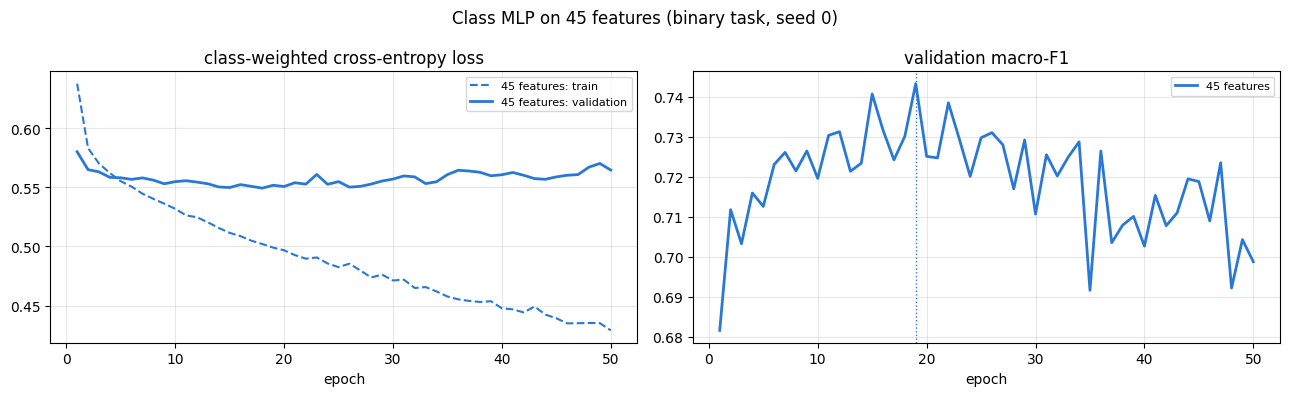

In [7]:
def plot_curves(keys_labels, title, name):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for (inp, task, cfg), (label, color) in keys_labels.items():
        h = HISTORIES[(inp, task)][(cfg, 0)]
        axes[0].plot(h["epoch"], h["train_loss"], "--", color=color, lw=1.5, label=f"{label}: train")
        axes[0].plot(h["epoch"], h["val_loss"], "-", color=color, lw=2, label=f"{label}: validation")
        axes[1].plot(h["epoch"], h["val_macro_f1"], "-", color=color, lw=2, label=label)
        best = int(h["val_macro_f1"].idxmax()) + 1
        axes[1].axvline(best, color=color, ls=":", lw=1)
    axes[0].set_title("class-weighted cross-entropy loss"); axes[0].set_xlabel("epoch")
    axes[1].set_title("validation macro-F1"); axes[1].set_xlabel("epoch")
    for a in axes: a.grid(alpha=0.3); a.legend(fontsize=8)
    plt.suptitle(title); plt.tight_layout(); save(name); plt.show()

plot_curves({("45 features", "binary", "class MLP (64)"): ("45 features", COLORS["features"])},
            "Class MLP on 45 features (binary task, seed 0)", "curves_features")

**Observation Exercise 1.**
- **Configurations:** on the 45 features the three configurations are practically tied on validation (binary
  0.745 / 0.747 / 0.750; seed-to-seed spread ±0.002–0.004). Size and depth hardly matter here, because the input is
  only 45 numbers.
- **Curves:** the training loss keeps falling for all 50 epochs. The validation loss stops improving after about
  5 epochs and then slowly rises, which is mild overfitting (Session 6 "Overfitting, revisited"). Validation macro-F1
  peaks around epoch 20, and early stopping keeps that epoch (average best epoch ≈ 22 for the binary task).
- **Compared with Session 5:** the MLP on the same 45 features reaches **0.728 ± 0.001 test macro-F1** (binary),
  against **0.721** for the SVM. That is +0.007, well inside the SVM's 95 % test interval [0.691, 0.751], so it is a
  **tie**. On the 33 Session 5 features the MLP gets 0.713. The 45 features stay better, as in Milestone 2.

---
## Exercise 2 — `nn.Conv2d` and Session 4

From the PyTorch documentation (`torch.nn.Conv2d`, PyTorch 2.x):

```
nn.Conv2d(in_channels, out_channels, kernel_size, stride=1, padding=0, dilation=1,
          groups=1, bias=True, padding_mode='zeros', device=None, dtype=None)
```

| Session 4 concept | `nn.Conv2d` argument | what the docs say | Session 4 example |
|---|---|---|---|
| **kernel size** (3×3 box blur, Sobel) | **`kernel_size`** (int or tuple) | "size of the convolving kernel" | `kernel_size=3` |
| **stride** (jump 2 pixels to downsample) | **`stride`** (default 1) | "stride of the convolution" | `stride=2` → 5×5 becomes 2×2 |
| **padding** (add a border so the output keeps its size) | **`padding`** (default 0; int, tuple, or `'valid'` / `'same'`) | "padding added to all four sides of the input" | `padding=1` → 5×5 stays 5×5 |
| **zero vs mirror padding** | **`padding_mode`** (`'zeros'`, `'reflect'`, `'replicate'`, `'circular'`) | how the border is filled | `'zeros'` → dark frame 44.4; `'reflect'` → 100 |

**Output size.** The docs give $H_{out} = \lfloor (H_{in} + 2\cdot\text{padding} - \text{dilation}\cdot(\text{kernel\_size}-1) - 1)/\text{stride} \rfloor + 1$.
With `dilation=1` this is exactly Session 4's $\lfloor (n + 2p - k)/s \rfloor + 1$.

**What is new compared with Session 4**
- `in_channels` / `out_channels`: a layer reads all colour channels at once and applies **many kernels in
  parallel** (one output channel per kernel). The weights have shape `(out_channels, in_channels, k, k)`.
- **The kernel values are not chosen by us.** They are learnable parameters (`conv.weight`), initialised at
  random and trained by backpropagation, plus one learnable `bias` per output channel.
- `dilation` (gaps inside the kernel) and `groups` have no Session 4 counterpart.
- PyTorch computes a **cross-correlation** (the kernel is not flipped), which is exactly how the kernels were
  slid over the image in Session 4.

**Check in code.** I set the kernel of an `nn.Conv2d` by hand and apply it to the Session 4 toy lesion. It must
give the numbers computed by hand on the slides (the same checks are in `tests/test_mlp.py`).

In [8]:
TOY = torch.tensor([[100, 100, 100, 100, 100],
                    [100, 100, 100, 100, 100],
                    [100, 100, 10, 10, 10],
                    [100, 100, 10, 10, 10],
                    [100, 100, 10, 10, 10]], dtype=torch.float32).view(1, 1, 5, 5)   # (batch, channels, H, W)

def conv_with(kernel, **kwargs):
    conv = nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3, bias=False, **kwargs)
    with torch.no_grad():
        conv.weight[:] = torch.tensor(kernel, dtype=torch.float32).view(1, 1, 3, 3)
    return conv

BOX = np.ones((3, 3)) / 9
SOBEL_X = [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]
cases = {
    "box blur, kernel_size=3 (stride 1, no padding)": conv_with(BOX),
    "box blur, stride=2": conv_with(BOX, stride=2),
    "box blur, padding=1 (zeros)": conv_with(BOX, padding=1),
    "box blur, padding=1, padding_mode='reflect'": conv_with(BOX, padding=1, padding_mode="reflect"),
    "Sobel Gx, kernel_size=3": conv_with(SOBEL_X),
}
with torch.no_grad():
    for title, conv in cases.items():
        out = conv(TOY)[0, 0]
        print(f"{title}  ->  output {tuple(out.shape)}\n{out.numpy().round(1)}\n")

box blur, kernel_size=3 (stride 1, no padding)  ->  output (3, 3)
[[90. 80. 70.]
 [80. 60. 40.]
 [70. 40. 10.]]

box blur, stride=2  ->  output (2, 2)
[[90. 70.]
 [70. 10.]]

box blur, padding=1 (zeros)  ->  output (5, 5)
[[44.4 66.7 66.7 66.7 44.4]
 [66.7 90.  80.  70.  46.7]
 [66.7 80.  60.  40.  26.7]
 [66.7 70.  40.  10.   6.7]
 [44.4 46.7 26.7  6.7  4.4]]

box blur, padding=1, padding_mode='reflect'  ->  output (5, 5)
[[100. 100. 100. 100. 100.]
 [100.  90.  80.  70.  70.]
 [100.  80.  60.  40.  40.]
 [100.  70.  40.  10.  10.]
 [100.  70.  40.  10.  10.]]

Sobel Gx, kernel_size=3  ->  output (3, 3)
[[ -90.  -90.    0.]
 [-270. -270.    0.]
 [-360. -360.    0.]]



All five outputs match the Session 4 slides: box blur 3×3 = [[90, 80, 70], [80, 60, 40], [70, 40, 10]];
stride 2 = [[90, 70], [70, 10]]; zero padding gives the dark corner 44.4 and mirror padding gives 100;
Sobel Gx = [[−90, −90, 0], [−270, −270, 0], [−360, −360, 0]].

**Why this matters for Exercise 3: parameters.** A convolution re-uses the same small kernel at every position.

In [9]:
layers = {"nn.Linear(3072, 64)   (MLP on 32x32x3 pixels)": nn.Linear(3072, 64),
          "nn.Conv2d(3, 64, kernel_size=3)": nn.Conv2d(3, 64, kernel_size=3),
          "nn.Conv2d(3, 64, kernel_size=3, stride=2, padding=1)": nn.Conv2d(3, 64, 3, stride=2, padding=1)}
x = torch.zeros(1, 3, 32, 32)
pd.DataFrame({"parameters": {k: mlp.n_parameters(l) for k, l in layers.items()},
              "output for one 32x32x3 image": {k: str(tuple((l(x.flatten(1)) if isinstance(l, nn.Linear) else l(x)).shape))
                                               for k, l in layers.items()}})

,parameters,output for one 32x32x3 image
"nn.Linear(3072, 64) (MLP on 32x32x3 pixels)",196672,"(1, 64)"
"nn.Conv2d(3, 64, kernel_size=3)",1792,"(1, 64, 30, 30)"
"nn.Conv2d(3, 64, kernel_size=3, stride=2, padding=1)",1792,"(1, 64, 16, 16)"


---
## Exercise 3 — The same MLP on raw pixels (32 × 32 × 3 = 3,072 numbers)

Every image is shrunk to 32×32 pixels (the whole image, not a crop) and flattened into one row of 3,072 numbers.
Each pixel position and channel is standardised with the train mean/std. Then the same 3 configurations ×
3 seeds as in Exercise 1 are trained.

  1000/5240 images (2s)
  2000/5240 images (4s)
  3000/5240 images (6s)
  4000/5240 images (9s)
  5000/5240 images (11s)
  5240/5240 images (12s)


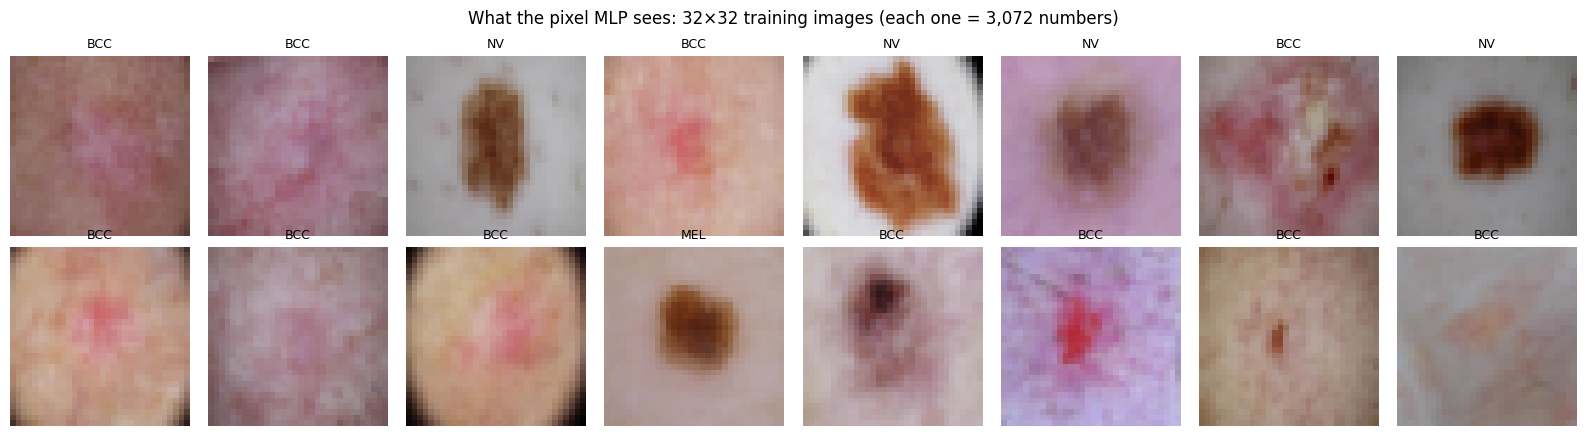

In [10]:
pix = mlp.load_pixels(pd.concat([train, val, test]), image_paths, size=32, cache_path=OUT / "pixels32.npz")
n_tr, n_va = len(train), len(val)
P = {"train": pix[:n_tr], "val": pix[n_tr:n_tr + n_va], "test": pix[n_tr + n_va:]}

fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, i in zip(axes.flat, np.random.default_rng(config.SEED).choice(n_tr, 16, replace=False)):
    ax.imshow(P["train"][i]); ax.set_title(f"{train['dx'][i]}", fontsize=9); ax.axis("off")
plt.suptitle("What the pixel MLP sees: 32×32 training images (each one = 3,072 numbers)")
plt.tight_layout(); save("pixels32"); plt.show()

In [11]:
X_pix = {s: P[s].reshape(len(P[s]), -1).astype(np.float64) for s in P}     # flatten: (N, 3072)
for task in TASKS:
    experiment("raw pixels 32x32x3", X_pix, task)
show_results("raw pixels 32x32x3")

  raw pixels 32x32x3 / binary  class MLP (64)             mean val macro-F1 = 0.725
  raw pixels 32x32x3 / binary  wide (256) + dropout/wd    mean val macro-F1 = 0.724
  raw pixels 32x32x3 / binary  deep (64,64) + dropout/wd  mean val macro-F1 = 0.735
  raw pixels 32x32x3 / 3-class class MLP (64)             mean val macro-F1 = 0.526
  raw pixels 32x32x3 / 3-class wide (256) + dropout/wd    mean val macro-F1 = 0.527
  raw pixels 32x32x3 / 3-class deep (64,64) + dropout/wd  mean val macro-F1 = 0.540


val_macro_f1_mean  val_macro_f1_sd  \
task    config                                                          
binary  class MLP (64)                         0.725            0.003   
        wide (256) + dropout/wd                0.724            0.003   
        deep (64,64) + dropout/wd              0.735            0.002   
3-class class MLP (64)                         0.526            0.010   
        wide (256) + dropout/wd                0.527            0.002   
        deep (64,64) + dropout/wd              0.540            0.005   

                                   best_epoch_mean  n_params  
task    config                                                
binary  class MLP (64)                      11.000    196802  
        wide (256) + dropout/wd             26.667    787202  
        deep (64,64) + dropout/wd           19.333    200962  
3-class class MLP (64)                      31.000    196867  
        wide (256) + dropout/wd             21.667    787459  
        deep (64,64) + dropout/wd           38.333    201027

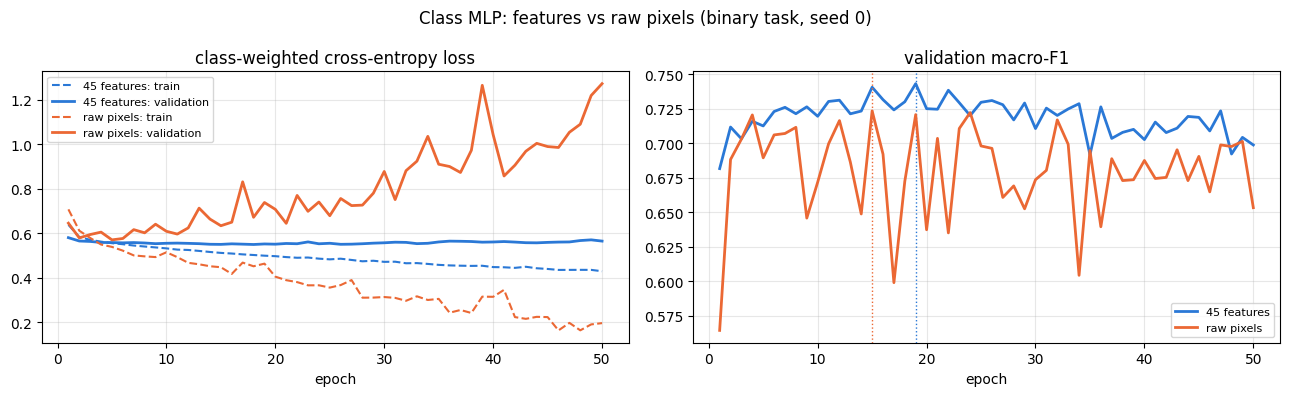

In [12]:
plot_curves({("45 features", "binary", "class MLP (64)"): ("45 features", COLORS["features"]),
             ("raw pixels 32x32x3", "binary", "class MLP (64)"): ("raw pixels", COLORS["pixels"])},
            "Class MLP: features vs raw pixels (binary task, seed 0)", "curves_features_vs_pixels")

### Does the MLP use the arrangement of the pixels? A shuffling test
The pixel order is scrambled with **one fixed random permutation**, the same for every image, so neighbouring
pixels are no longer neighbours. For a human (or a CNN) the images become noise. If the MLP scores the same,
it never used the spatial arrangement at all.

  shuffled pixels / binary     deep (64,64) + dropout/wd  mean val macro-F1 = 0.733
  shuffled pixels / 3-class    deep (64,64) + dropout/wd  mean val macro-F1 = 0.542


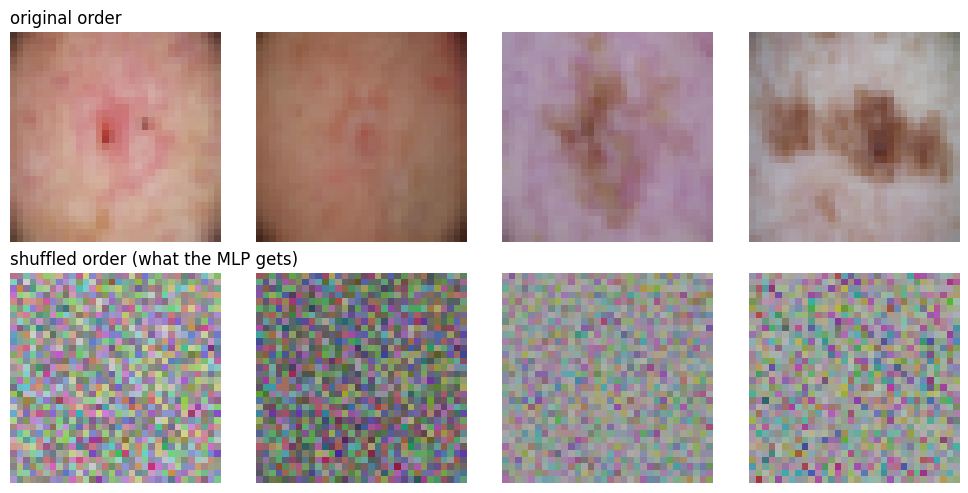

,input,task,chosen config,val mean,val sd,test mean,test sd
0,raw pixels 32x32x3,binary,"deep (64,64) + dropout/wd",0.735,0.002,0.728,0.006
1,raw pixels 32x32x3,3-class,"deep (64,64) + dropout/wd",0.540,0.005,0.525,0.008
2,shuffled pixels,binary,"deep (64,64) + dropout/wd",0.733,0.004,0.731,0.003
3,shuffled pixels,3-class,"deep (64,64) + dropout/wd",0.542,0.004,0.505,0.020


In [13]:
perm = np.random.default_rng(config.SEED).permutation(3072)
X_shuf = {s: X_pix[s][:, perm] for s in X_pix}
for task in TASKS:
    cfg = SUMMARY[("raw pixels 32x32x3", task)]["chosen config"]
    col, n_classes = TASKS[task]
    scaler = mlp.Standardizer().fit(X_shuf["train"])
    Xs = {s: scaler.transform(X_shuf[s]) for s in X_shuf}
    res, models, _ = mlp.run_configs(Xs["train"], Y[task]["train"], Xs["val"], Y[task]["val"], n_classes,
                                     configs={cfg: mlp.CONFIGS[cfg]}, label=f"shuffled pixels / {task}")
    f1s = [f1_score(Y[task]["test"], mlp.predict_proba(models[(cfg, s)], Xs["test"]).argmax(1), average="macro")
           for s in mlp.SEEDS]
    SUMMARY[("shuffled pixels", task)] = {"input": "shuffled pixels", "task": task, "chosen config": cfg,
                                          "val mean": res["val_macro_f1"].mean(), "val sd": res["val_macro_f1"].std(),
                                          "test mean": np.mean(f1s), "test sd": np.std(f1s, ddof=1)}

ex = np.random.default_rng(1).choice(n_tr, 4, replace=False)
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for j, i in enumerate(ex):
    axes[0, j].imshow(P["train"][i]); axes[1, j].imshow(P["train"][i].reshape(-1)[perm].reshape(32, 32, 3))
    axes[0, j].axis("off"); axes[1, j].axis("off")
axes[0, 0].set_title("original order", loc="left"); axes[1, 0].set_title("shuffled order (what the MLP gets)", loc="left")
plt.tight_layout(); save("shuffled_pixels"); plt.show()

pd.DataFrame([SUMMARY[(k, t)] for k in ["raw pixels 32x32x3", "shuffled pixels"] for t in TASKS])[
    ["input", "task", "chosen config", "val mean", "val sd", "test mean", "test sd"]].round(3)

**Observation Exercise 3.**
- **Pixels vs features:**
  - **Binary:** the pixel MLP reaches **0.735 ± 0.002** validation and **0.728 ± 0.006** test macro-F1. The MLP on
    45 features gets 0.750 / 0.728, and the SVM 0.741 / 0.721. So pixels are lower on validation (by 0.015, much
    more than the seed noise of 0.002) and equal on test.
  - **3 classes:** pixels are clearly worse: 0.540 / 0.525 against 0.559 / 0.549 for the 45 features.
- **Shuffling test:** with the pixel order scrambled (images that look like pure noise to us), the MLP scores the
  same: binary 0.733 / 0.731, 3-class 0.542 / 0.505, against 0.735 / 0.728 and 0.540 / 0.525 unscrambled.
  **The MLP does not use which pixels are next to each other.**
- **Curves:** the class MLP has **196,802 parameters for 3,143 training images** (63 per image; the 45-feature
  version has 3,074). It memorises fast: its training loss falls to about 0.2 while the validation loss more than
  doubles (0.58 → 1.27). The validation macro-F1 jumps by ±0.05 from one epoch to the next, and the best epoch comes
  early. Early stopping is what keeps it competitive.

---
## The scoreboard
Macro-F1, same split for every row. MLP rows: mean ± standard deviation over 3 training seeds of the
configuration chosen on validation. The test split was used once per row.

In [14]:
def majority(task):
    col, _ = TASKS[task]
    m = int(pd.Series(Y[task]["train"]).mode()[0])
    return {s: f1_score(Y[task][s], np.full(len(Y[task][s]), m), average="macro",
                        labels=list(range(TASKS[task][1]))) for s in ["val", "test"]}

def fmt(mean, sd=None):
    return f"{mean:.3f}" if sd is None or np.isnan(sd) else f"{mean:.3f} ± {sd:.3f}"

rows = []
maj = {t: majority(t) for t in TASKS}
rows.append({"model": "majority class (floor)", "input": "—", "chosen config (binary / 3-class)": "—", "parameters": 0,
             **{f"{t} {s}": fmt(maj[t][s]) for t in TASKS for s in ["val", "test"]}})
b = {"binary": baseline["binary"], "3-class": baseline["three_class"]}
rows.append({"model": "Session 5 baseline: SVM", "input": "45 features",
             "chosen config (binary / 3-class)": "RBF, C=3 / RBF, C=3", "parameters": "—",
             "binary val": fmt(b["binary"]["validation"]["macro_f1"]),
             "binary test": fmt(b["binary"]["test_default_threshold"]["macro_f1"]),
             "3-class val": fmt(b["3-class"]["validation"]["macro_f1"]),
             "3-class test": fmt(b["3-class"]["test"]["macro_f1"])})
for inp in ["33 features (Session 5)", "45 features", "raw pixels 32x32x3"]:
    r = {"model": "MLP", "input": inp,
         "chosen config (binary / 3-class)": " / ".join(SUMMARY[(inp, t)]["chosen config"] for t in TASKS),
         "parameters": SUMMARY[(inp, "binary")]["n_params"]}
    for t in TASKS:
        r[f"{t} val"] = fmt(SUMMARY[(inp, t)]["val mean"], SUMMARY[(inp, t)]["val sd"])
        r[f"{t} test"] = fmt(SUMMARY[(inp, t)]["test mean"], SUMMARY[(inp, t)]["test sd"])
    rows.append(r)
scoreboard = pd.DataFrame(rows)
scoreboard.to_csv(OUT / "scoreboard.csv", index=False)
scoreboard

,model,input,chosen config (binary / 3-class),parameters,binary val,binary test,3-class val,3-class test
0,majority class (floor),—,—,0,0.418,0.417,0.272,0.273
1,Session 5 baseline: SVM,45 features,"RBF, C=3 / RBF, C=3",—,0.741,0.721,0.567,0.518
2,MLP,33 features (Session 5),wide (256) + dropout/wd / wide (256) + dropout/wd,9218,0.738 ± 0.002,0.713 ± 0.001,0.537 ± 0.005,0.492 ± 0.000
3,MLP,45 features,"deep (64,64) + dropout/wd / wide (256) + dropo...",7234,0.750 ± 0.002,0.728 ± 0.001,0.559 ± 0.002,0.549 ± 0.006
4,MLP,raw pixels 32x32x3,"deep (64,64) + dropout/wd / deep (64,64) + dro...",200962,0.735 ± 0.002,0.728 ± 0.006,0.540 ± 0.005,0.525 ± 0.008


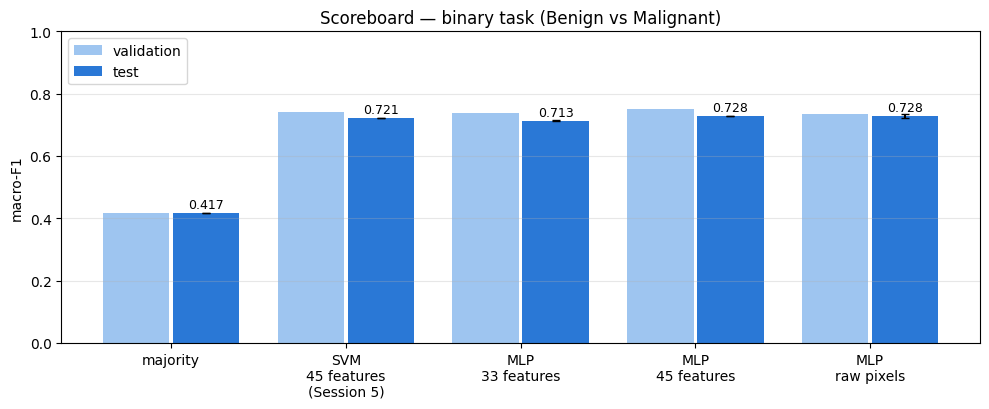

In [15]:
labels = ["majority", "SVM\n45 features\n(Session 5)", "MLP\n33 features", "MLP\n45 features", "MLP\nraw pixels"]
val_b = [maj["binary"]["val"], b["binary"]["validation"]["macro_f1"]] + \
        [SUMMARY[(i, "binary")]["val mean"] for i in ["33 features (Session 5)", "45 features", "raw pixels 32x32x3"]]
test_b = [maj["binary"]["test"], b["binary"]["test_default_threshold"]["macro_f1"]] + \
         [SUMMARY[(i, "binary")]["test mean"] for i in ["33 features (Session 5)", "45 features", "raw pixels 32x32x3"]]
sd_b = [0, 0] + [SUMMARY[(i, "binary")]["test sd"] for i in ["33 features (Session 5)", "45 features", "raw pixels 32x32x3"]]
xpos = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(xpos - 0.2, val_b, 0.38, color="#9ec5f0", label="validation")
ax.bar(xpos + 0.2, test_b, 0.38, yerr=sd_b, capsize=3, color="#2a78d6", label="test")
for x_, v in zip(xpos + 0.2, test_b):
    ax.text(x_, v + 0.015, f"{v:.3f}", ha="center", fontsize=9)
ax.set_xticks(xpos, labels); ax.set_ylabel("macro-F1"); ax.set_ylim(0, 1)
ax.set_title("Scoreboard — binary task (Benign vs Malignant)"); ax.legend(loc="upper left"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); save("scoreboard"); plt.show()

In [16]:
pd.concat(ALL_RESULTS).to_csv(OUT / "val_results_all_runs.csv", index=False)
json.dump({f"{k[0]} | {k[1]}": {kk: (float(vv) if isinstance(vv, (float, np.floating)) else vv)
                                for kk, vv in v.items() if kk != "best epochs"} | {"best epochs": [int(e) for e in v.get("best epochs", [])]}
           for k, v in SUMMARY.items()}, open(OUT / "summary.json", "w"), indent=2)
print("saved:", sorted(p.name for p in OUT.iterdir()))

saved: ['pixels32.npz', 'scoreboard.csv', 'summary.json', 'val_results_all_runs.csv']


---
## Answers

**1. Scoreboard.** Macro-F1, same lesion-level split; MLP = mean ± sd over 3 seeds of the configuration chosen on validation.

| model | input | parameters | binary val | **binary test** | 3-class val | **3-class test** |
|---|---|---|---|---|---|---|
| majority class (floor) | — | 0 | 0.418 | 0.417 | 0.272 | 0.273 |
| **Session 5 baseline: SVM (RBF, C=3)** | 45 features | — | 0.741 | **0.721** | 0.567 | **0.518** |
| MLP (wide 256, dropout/wd) | 33 features (Session 5) | 9,218 | 0.738 ± 0.002 | 0.713 ± 0.001 | 0.537 ± 0.005 | 0.492 ± 0.000 |
| **MLP** (binary: 64-64, 3-class: 256; dropout/wd) | 45 features | 7,234 | 0.750 ± 0.002 | **0.728 ± 0.001** | 0.559 ± 0.002 | **0.549 ± 0.006** |
| MLP (64-64, dropout/wd) | raw pixels 32×32×3 | 200,962 | 0.735 ± 0.002 | 0.728 ± 0.006 | 0.540 ± 0.005 | 0.525 ± 0.008 |

On the same 45 features, the MLP **ties** the Session 5 SVM on the project task (test 0.728 vs 0.721, inside the
SVM's 95 % interval 0.691–0.751). On 3 classes it is higher on test (0.549 vs 0.518) but lower on validation
(0.559 vs 0.567). With only 23 *Indeterminate* lesions in test, that difference is within the noise.
**Conclusion:** a network that learns its own intermediate features *on top of* our 45 numbers adds almost nothing.
The limit is the information in the handcrafted features, not the classifier. This matches Milestone 2, where the
choice of features mattered much more than the choice of model.

**2. `nn.Conv2d`.** Session 4's kernel size is **`kernel_size`**, the stride is **`stride`** and the padding is
**`padding`** (with **`padding_mode`** choosing zero padding `'zeros'` or mirror padding `'reflect'`). The output
size follows the same formula, ⌊(n + 2p − k)/s⌋ + 1. The difference: in Session 4 we chose the kernel values
(box, Gaussian, Sobel). In `nn.Conv2d` they are learnable weights of shape `(out_channels, in_channels, k, k)`,
trained by backpropagation, with many kernels per layer and all colour channels read at once.

**3. Raw pixels vs features: not better. Slightly worse on validation and on 3 classes, equal on the binary test.**
On the binary task the pixel MLP gets 0.735 validation and 0.728 test, against 0.750 / 0.728 for the same MLP on
features and 0.741 / 0.721 for the Session 5 SVM. On 3 classes it is clearly worse (test 0.525 vs 0.549).

**Why it is not better:**
1. **The MLP ignores the spatial structure.** It treats the 3,072 numbers as unrelated inputs: scrambling the pixel
   order gives the same score (shuffling test). So it cannot build what needs *neighbouring* pixels: edges, texture,
   the lesion border and its shape. Those are exactly what the handcrafted features measured (edge density, GLCM,
   mask compactness, skin–lesion contrast).
2. **No translation invariance.** A lesion a few pixels off-centre activates completely different weights, so the
   network must learn the same pattern separately at every position.
3. **Too many parameters for the data.** 196,802–200,962 weights for 3,143 images: the network memorises the
   training set within a few epochs (training loss → 0.2, validation loss 0.58 → 1.27). Only early stopping and
   regularisation keep it usable.
4. **32×32 throws away detail.** The pigment network and fine texture disappear at that size, while the features
   were measured at 256×256.

**Why it is still almost as good:** in Milestone 2, colour carried most of the signal (colour-only SVM 0.724
validation, texture alone 0.595). A 32×32 image still contains all the colour information and the rough position of
the dark lesion. A weighted sum of pixels can learn colour averages similar to the colour statistics and histograms.

**What would fix it — Exercise 2.** An `nn.Conv2d` layer slides one small learned kernel over every position. It uses
the neighbourhood, recognises a pattern wherever it appears, and needs about 100× fewer parameters: 1,792 for 64
kernels of 3×3×3, against 196,672 for `nn.Linear(3072, 64)`. That is the CNN of Session 7.